# OlmoEarth: annual Sentinel-1/2 embeddings with native `predict_onnx`

An **embedding** is a vector of learned features, not a land-cover label. Here we build twelve calendar-month composites of **Mol, Belgium, in 2024**, pass both satellite time series through Ai2's pretrained **OlmoEarth v1.2**, and produce **one annual feature cube at 40 m**. **Nano is the default (128 bands)**; Tiny, Small and Base produce 192, 384 and 768 bands respectively. The saved figures and outputs below are from the validated **Nano** run. Save the cube once and reuse it for downstream classification, clustering or similarity analysis. We visualize it with PCA; we do not train or assess a classifier.

```text
S2 + SCL cloud mask → monthly median ─┐
                                     ├→ 12 × 17 packed bands → predict_onnx → annual D-band cube
S1 VV/VH → linear monthly mean → dB ─┘                                      ↓
                                                                    GeoTIFF + PCA
```

All twelve months and both modalities attend **jointly and bidirectionally within each 320 m spatial tile**. This is retrospective annual representation learning, not twelve independent maps or a causal, as-of-date prediction. Missing modality/month tokens are masked and excluded from pooling. No model training, UDF, Python dependency archive or backend modification is needed.

This example targets **Copernicus Data Space Ecosystem (CDSE)** and its experimental native `predict_onnx` STAC support. Ai2's **[OlmoEarth Artifact License](https://huggingface.co/allenai/OlmoEarth-v1_2-Nano/blob/e1f693ae2a7d5b57871a978e9d09e22d05206747/LICENSE.txt)** restricts uses of model artifacts and derivatives; read **[README: licensing](./README.md#licensing)** before using or sharing them.


## About OlmoEarth

[OlmoEarth](https://github.com/allenai/olmoearth_pretrain) is Ai2's family of **multimodal, spatiotemporal foundation models for Earth observation**. Its pretrained encoders transform satellite images and time series into reusable learned features for downstream tasks such as classification and segmentation. The official models support Sentinel-1, Sentinel-2 and Landsat imagery; this notebook uses **Sentinel-1 and Sentinel-2 only**. These features are not themselves land-cover predictions.

We default to **[OlmoEarth v1.2 Nano](https://huggingface.co/allenai/OlmoEarth-v1_2-Nano)**, the smallest v1.2 variant, for a compact CPU-based ONNX demonstration—not as a claim that it is the best model for every task. Select Tiny, Small or Base in the configuration after exporting that variant. Larger encoders do not expand the fixed 320 m tile context. We retain the pretrained weights and adapt the inference interface for openEO, pooling twelve monthly observations into one annual representation. This interface and valid-only pooling are adaptations in this example, **not a separately trained official annual OlmoEarth model**.

The resulting vectors at 40 m are visualized with PCA; no downstream classifier is trained. Features from different variants are not interchangeable: retrain downstream models rather than mixing them. See [README: model overview](./README.md#about-olmoearth) for the model family, technical report and references, and [README: licensing](./README.md#licensing) for the restricted-use terms.


## 1. Prepare the environment and model

Start Jupyter in this directory. See [README](./README.md#quick-start) for the complete commands.

1. **Offline, once:** use `requirements-export.txt`, run `python export_olmoearth_to_onnx.py --variant nano`, then `python check_olmoearth_onnx.py --variant nano`. Replace `nano` with `tiny`, `small` or `base` for another variant. The exporter downloads a pinned official checkpoint and verifies its SHA-256. It embeds normalization and weights in a single ONNX file (~5.7 MB for Nano).
2. **Notebook:** `requirements.txt` is sufficient; PyTorch and OlmoEarth are **not** imported here. Keep the exported ONNX and its STAC JSON next to this notebook. Neither binary models nor downloaded results belong in Git.

We keep the openEO processing visible below. The small companion module contains only model/band metadata, calendar helpers and local contract/result checks.


In [1]:
from pathlib import Path
from datetime import date
import json

import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt
import rasterio
from matplotlib.ticker import MultipleLocator
from openeo.rest.connection import connect
from openeo.rest.multiresult import MultiResult
from openeo.extra.artifacts.artifact_helper import build_artifact_helper
from openeo.processes import if_, is_nan, log
from openeo_olmoearth import (
    MODELS, S2_BANDS, INPUT_BANDS, model_name, validate_contract,
    calendar_months, patch_validity, check_results,
)

ROOT = Path.cwd()
assert (ROOT / 'openeo_olmoearth.py').exists(), 'Start Jupyter from the olmoearth example directory'


## 2. Choose the model variant, area and year

The demonstrated footprint is 2.56 × 2.56 km near VITO in Mol. **Keep these defaults for the first run.** The grid and preprocessing are deliberately explicit rather than presented as a globally validated service.

Choose `VARIANT` from `nano`, `tiny`, `small`, `base`; export and check the matching model first. Every variant keeps the same 32×32 input and 40 m output spacing. Larger variants need more memory and compute. All four passed small 320 m Mol tests with the 6 GB executor setting; only Nano has been backend-validated on the full default footprint. Start larger-variant experiments with a small area: this is not a large-AOI resource guarantee. See the README for model sizes and validated scope.

`JOB_ID = None` creates a new job. After submission, copy the printed identifier here to resume your **own** job in a later session; other users cannot access the author's jobs. Reset it if changing the **variant**, year or area, and rerun configuration and later cells. The extra input export below is for reproducibility and teaching, not a requirement for every downstream application.


In [2]:
VARIANT = 'nano'
BACKEND = 'https://openeo.dataspace.copernicus.eu'
YEAR = 2024
EXTENT = {'west': 644930, 'south': 5674970, 'east': 647490, 'north': 5677530, 'crs': 32631}
JOB_ID = None  # Set your own existing job identifier to resume instead of submitting again.
JOB_OPTIONS = {
    'driver-memory': '4G', 'executor-memory': '6G',
    'executor-memoryOverhead': '2G', 'executor-cores': 1,
}
assert VARIANT in MODELS
MODEL_PATH = ROOT / f'{model_name(VARIANT)}.onnx'
STAC_PATH = MODEL_PATH.with_suffix('.stac.json')
assert MODEL_PATH.exists() and STAC_PATH.exists(), 'Run the offline exporter and checker for this variant first'


## 3. Connect and authenticate

Use a CDSE account with openEO access. The standard OIDC flow prompts on first use and normally reuses cached credentials later. Never paste tokens into this notebook.

Check the advertised processes **before** building a job. This is CDSE-specific: another backend may not support the ONNX/STAC path, cloud-mask process, artifacts or job options even if it offers the same satellite collections.


In [3]:
connection = connect(BACKEND).authenticate_oidc()
required = {
    'aggregate_temporal', 'predict_onnx', 'sar_backscatter', 'to_scl_dilation_mask',
    'convert_data_type', 'resample_cube_spatial',
}
available = {p['id'] for p in connection.list_processes()}
assert required <= available, f'Backend missing processes: {sorted(required - available)}'
print('Connected; required processes are advertised')


Authenticated using refresh token.


Connected; required processes are advertised


## 4. Define twelve calendar months

`aggregate_temporal` uses explicit **half-open** intervals: `[start, end)`. February in 2024 has 29 days; these are calendar months, not twelve fixed 30-day windows. Each composite receives its interval's midpoint date as `[day, zero-based month, year]` for OlmoEarth. A midpoint represents the composite, **not an individual capture date**.

Explicit labels preserve the intended order. A month without valid measurements must stay missing; we must not silently substitute a neighbouring month. Cloud-masked nodata is tested locally and in the demonstrated year, but an **entirely absent acquisition month** has not been tested end-to-end on the backend.


In [4]:
intervals, timestamps = calendar_months(YEAR)
month_labels = [interval[0] for interval in intervals]
temporal_extent = [intervals[0][0], intervals[-1][1]]
assert len(intervals) == len(timestamps) == 12
assert temporal_extent == [f'{YEAR}-01-01', f'{YEAR + 1}-01-01']
assert [t[1] for t in timestamps] == list(range(12))
assert calendar_months(2024)[0][1] == ['2024-02-01', '2024-03-01']
assert (date(2024, 3, 1) - date(2024, 2, 1)).days == 29
for interval, timestamp in zip(intervals, timestamps):
    print(interval, '→', timestamp)


['2024-01-01', '2024-02-01'] → [16, 0, 2024]
['2024-02-01', '2024-03-01'] → [15, 1, 2024]
['2024-03-01', '2024-04-01'] → [16, 2, 2024]
['2024-04-01', '2024-05-01'] → [16, 3, 2024]
['2024-05-01', '2024-06-01'] → [16, 4, 2024]
['2024-06-01', '2024-07-01'] → [16, 5, 2024]
['2024-07-01', '2024-08-01'] → [16, 6, 2024]
['2024-08-01', '2024-09-01'] → [16, 7, 2024]
['2024-09-01', '2024-10-01'] → [16, 8, 2024]
['2024-10-01', '2024-11-01'] → [16, 9, 2024]
['2024-11-01', '2024-12-01'] → [16, 10, 2024]
['2024-12-01', '2025-01-01'] → [16, 11, 2024]


## 5. Sentinel-2: mask first, then make monthly medians

OlmoEarth requires **all twelve bands**, including B01 and B09, in the displayed positional order. The native 10/20/60 m bands are placed on one 10 m grid using nearest-neighbour resampling; this does not add detail to coarser bands.

We use the WorldCereal-style SCL erosion/dilation parameters. A separate **1 km SCL halo** gives the 17/77-pixel cloud-mask kernels surrounding context before clipping to the requested area. Apply the mask to each acquisition **before** taking monthly medians, so cloud values do not enter the reducer.

CDSE already harmonizes Sentinel-2 processing-baseline DN offsets. **Do not subtract another 1000, divide by 10000, or apply normalization here.** OlmoEarth's official computed normalization is embedded in ONNX; this graph passes harmonized DN.


In [5]:
optical = connection.load_collection(
    'SENTINEL2_L2A', bands=S2_BANDS, spatial_extent=EXTENT,
    temporal_extent=temporal_extent, properties={'eo:cloud_cover': lambda x: x <= 95},
).resample_spatial(resolution=10, projection=EXTENT['crs'], method='near')

halo = dict(EXTENT)
for key in ['west', 'south']:
    halo[key] -= 1000
for key in ['east', 'north']:
    halo[key] += 1000
scl = connection.load_collection(
    'SENTINEL2_L2A', bands=['SCL'], spatial_extent=halo,
    temporal_extent=temporal_extent, properties={'eo:cloud_cover': lambda x: x <= 95},
).resample_spatial(resolution=10, projection=EXTENT['crs'], method='near')
cloud_mask = scl.process(
    'to_scl_dilation_mask', data=scl, scl_band_name='SCL',
    erosion_kernel_size=3, kernel1_size=17, kernel2_size=77,
    mask1_values=[2, 4, 5, 6, 7], mask2_values=[3, 8, 9, 10, 11],
).resample_cube_spatial(optical).filter_bbox(**EXTENT)
s2 = optical.mask(cloud_mask).aggregate_temporal(
    intervals=intervals, labels=month_labels, reducer='median', dimension='t',
).filter_bbox(**EXTENT)
print('S2 graph: cloud mask → twelve monthly medians; bands:', S2_BANDS)


S2 graph: cloud mask → twelve monthly medians; bands: ['B02', 'B03', 'B04', 'B08', 'B05', 'B06', 'B07', 'B8A', 'B11', 'B12', 'B01', 'B09']


## 6. Sentinel-1: average linear power, then convert to dB

Select one orbit direction (descending) and dual-polarization VV/VH. CDSE processes GRD with sigma0-ellipsoid, the COPERNICUS_30 elevation model and noise removal. We align it to the optical 10 m grid.

For each month, **average linear radar power first**, then compute `10 × log10(mean_power)` because OlmoEarth expects dB. Averaging dB directly is a different statistic. Non-positive power becomes nodata. Unlike the referenced WorldCereal pipeline, we apply **no custom uint16 radar encoding**.

A 10 m output grid does not turn radar into a 10 m independent-detail measurement.


In [6]:
radar = connection.load_collection(
    'SENTINEL1_GRD', bands=['VV', 'VH'], spatial_extent=EXTENT,
    temporal_extent=temporal_extent,
    properties={
        'sat:orbit_state': lambda x: x == 'DESCENDING',
        'polarisation': lambda x: x == 'VV&VH',
    },
).sar_backscatter(coefficient='sigma0-ellipsoid', elevation_model='COPERNICUS_30', noise_removal=True)
s1 = radar.resample_spatial(resolution=10, projection=EXTENT['crs'], method='near').resample_cube_spatial(s2)
s1 = s1.aggregate_temporal(intervals=intervals, labels=month_labels, reducer='mean', dimension='t')
s1 = s1.apply(lambda x: if_(x > 0, 10 * log(x, base=10), None))
print('S1 graph: twelve linear monthly means → dB')


S1 graph: twelve linear monthly means → dB


## 7. Transport the time axis as bands

Native `predict_onnx` accepts **one raster input**, not separate modality/timestamp tensors. Pack each month as **12 S2 + 2 S1 + 3 date channels = 17 bands**; twelve months make **204 float32 bands**. The model reconstructs the twelve-step time series internally. This packing does **not** run twelve separate encoder passes.

We select each explicit month and remove its singleton time dimension with `first`; the order assertion matters because ONNX consumes positions, not band names. Dates are constant even where B02 is nodata. The graph is lazy: no satellite processing has run yet.

A tiny synthetic check demonstrates the masking policy: **one missing pixel or band invalidates the entire 4×4 modality/month token**. Inside ONNX, invalid patch contents are safely replaced before patch interpolation, invalid tokens cannot serve as attention keys, and pooling averages valid months within each modality, then available modalities. A patch with no evidence in either modality remains nodata.


In [7]:
packed = None
for month, (interval, timestamp) in enumerate(zip(intervals, timestamps), start=1):
    optical_month = s2.filter_temporal(interval).reduce_dimension('t', reducer='first')
    radar_month = s1.filter_temporal(interval).reduce_dimension('t', reducer='first')
    monthly_cube = optical_month.merge_cubes(radar_month)
    for label, value in zip(['day', 'month0', 'year'], timestamp):
        constant = optical_month.band('B02').apply(lambda x: if_(is_nan(x), value, x * 0 + value))
        monthly_cube = monthly_cube.merge_cubes(constant.add_dimension('bands', label, type='bands'))
    monthly_cube = monthly_cube.rename_labels('bands', INPUT_BANDS[(month - 1) * 17:month * 17])
    packed = monthly_cube if packed is None else packed.merge_cubes(monthly_cube)
assert packed is not None and packed.metadata.band_names == INPUT_BANDS
cube = packed.process('convert_data_type', data=packed, data_type='float32')
graph = cube.flat_graph()
assert sum(n['process_id'] == 'aggregate_temporal' for n in graph.values()) == 2
assert sum(n['process_id'] == 'reduce_dimension' and n['arguments']['dimension'] == 't'
           for n in graph.values()) == 24
issues = cube.validate()
assert not issues, issues
del graph
probe = np.ones((204, 8, 8), dtype=np.float32)
probe[0, 0, 0] = np.nan
valid_probe = patch_validity(probe)
assert not valid_probe[0, 0, 0, 0] and valid_probe[:, 1].all() and valid_probe[1:].all()
print('Validated graph: 12 months × 17 bands =', len(INPUT_BANDS), 'float32 channels')
print('First month:', INPUT_BANDS[:17])


Validated graph: 12 months × 17 bands = 204 float32 channels
First month: ['m01_B02', 'm01_B03', 'm01_B04', 'm01_B08', 'm01_B05', 'm01_B06', 'm01_B07', 'm01_B8A', 'm01_B11', 'm01_B12', 'm01_B01', 'm01_B09', 'm01_VV', 'm01_VH', 'm01_day', 'm01_month0', 'm01_year']


## 8. Describe and upload the model

The exported **STAC MLM descriptor** names the tensor inputs/outputs and their shape, dtype and dimension order. The committed Nano descriptor is the shared baseline; the exporter generates a matching descriptor for each selected variant. **D = 128/192/384/768** for Nano/Tiny/Small/Base:

| Tensor | Shape | Meaning |
|---|---|---|
| `raster` | `[1, 204, 32, 32]` float32 | Twelve months of both modalities and dates |
| `annual_embeddings` | `[1, D, 8, 8]` float32 | One annual feature vector per 4×4 input patch |

Using STAC rather than a bare ONNX URL is important: this backend supports the **32→8 spatial downsampling through its STAC path**. Nested MLM metadata is duplicated as flat fields because the deployed backend reads those flat fields. The model contains its own weights and normalizer; no sidecar or UDF archive is required.

Upload the local model as a CDSE artifact and put its temporary presigned URL **only in the in-memory descriptor**. Do not display the graph, print URLs or write this populated descriptor to disk. On a resumed job, upload is skipped. The original JSON stays safe to commit.


In [8]:
stac = json.loads(STAC_PATH.read_text())
OUTPUT_BANDS = validate_contract(stac, VARIANT)
EMBEDDING_SIZE = len(OUTPUT_BANDS)
options = ort.SessionOptions(); options.intra_op_num_threads = 2
model_session = ort.InferenceSession(str(MODEL_PATH), options, providers=['CPUExecutionProvider'])
assert len(model_session.get_inputs()) == len(model_session.get_outputs()) == 1
inp, out = model_session.get_inputs()[0], model_session.get_outputs()[0]
assert inp.name == 'raster' and inp.shape == [1, 204, 32, 32] and inp.type == 'tensor(float)'
assert out.name == 'annual_embeddings' and out.shape == [1, EMBEDDING_SIZE, 8, 8] and out.type == 'tensor(float)'
del model_session
if JOB_ID is None:
    helper = build_artifact_helper(connection)
    model_uri = helper.upload_file(MODEL_PATH)
    stac['assets']['model']['href'] = helper.get_presigned_url(model_uri)
    print('Model uploaded; temporary URL retained only in memory')
else:
    print('Existing job configured: model upload skipped')


Model uploaded; temporary URL retained only in memory


## 9. Build the reusable embedding cube and submit once

The next cell explicitly calls native **`predict_onnx`** and restores the selected model's output labels. `annual` is the reusable feature cube: a downstream graph could consume it instead of immediately saving a raster.

For this small demonstration, save **two** GeoTIFFs in the same batch job: the packed monthly inputs and annual embeddings. Input export uses **`stitch=True` and `strict_cropping=False`** to preserve whole source tiles for numerical checks. Cropping inputs to the requested AOI would omit context used by boundary inference tiles; `strict_cropping=False` alone was insufficient on the tested writer. Stitching is for this small AOI, **not a scalable continental export strategy**.

The 40 m output uses the backend's native grid, so it may cover less than one extra cell beyond the requested AOI. Do not relabel its corner coordinates or assume a 64×64 output. We use the actual saved transform below.

**Submission is asynchronous. Run this cell once, then pause.** Note the printed job identifier and rerun status later; calling `start()` does not wait for completion. If `JOB_ID` is already configured, no new job is created. Signed model URLs expire, so rebuild/upload just before a new submission rather than saving the graph for later.


In [9]:
annual = cube.process('predict_onnx', data=cube, model=json.dumps(stac))
annual = annual.rename_labels('bands', OUTPUT_BANDS)
if JOB_ID is None:
    outputs = MultiResult([
        cube.save_result('GTiff', options={
            'filename_prefix': 'monthly-input', 'stitch': True, 'strict_cropping': False,
        }),
        annual.save_result('GTiff', options={'filename_prefix': 'annual-embeddings'}),
    ])
    job = outputs.create_job(title=f'OlmoEarth {VARIANT} community example — annual S1/S2 {YEAR}', job_options=JOB_OPTIONS)
    job.start()
    JOB_ID = job.job_id
    print('Submitted asynchronous job:', JOB_ID)
else:
    job = connection.job(JOB_ID)
    print('Resuming existing job:', JOB_ID)


Submitted asynchronous job: j-2610121159414bee85cc416b23fa72cd


## 10. Check status, then resume after completion

Rerun the following cell until the job is `finished`, or use the openEO editor. If it reports `error`/`canceled`, inspect its logs before resubmitting. Do not create another job just to check progress.

In a new session: set your saved `JOB_ID` in section 2, rerun the setup/graph cells (they remain lazy), then continue here. Upload and submission will be skipped. The download cell intentionally stops if the job is not yet finished.


In [10]:
assert JOB_ID, 'Submit once or configure your existing job identifier'
job = connection.job(JOB_ID)
status = job.status()
print(JOB_ID, status)
if status in {'error', 'canceled'}:
    raise RuntimeError('Inspect job logs in the openEO editor before resubmitting')


j-2610121159414bee85cc416b23fa72cd finished


## 11. Download and verify the actual product

The helper checks CRS, float32, 204 input bands and the selected model's output width/labels, date channels, 10/40 m spacing, native grid alignment, AOI coverage and nodata versus annual evidence. It then runs local **ONNX Runtime over complete input tiles** and compares **every saved output patch** (`rtol=1e-3`, `atol=1e-4`). This verifies preprocessing transport and numerical agreement, **not downstream accuracy**.

The stitched writer can emit `.tiff` and omit input band descriptions. We accept that known behavior because positional input order was asserted in the graph and dates are verified in the raster; output labels remain mandatory. Input previews are cropped to the output footprint **without resampling**, so the overlays have real shared coordinates.


In [11]:
if job.status() != 'finished':
    raise RuntimeError('Job is not finished; rerun the status cell later, then continue here')
folder = ROOT / 'results' / JOB_ID
job.get_results().download_files(folder, include_stac_metadata=False)
check_results(folder, MODEL_PATH, EXTENT, YEAR, VARIANT)
for path in folder.glob('*.tif*'):
    with rasterio.open(path) as src:
        if src.count == 204:
            input_path = path
        elif src.count == EMBEDDING_SIZE:
            embeddings = src.read(masked=True).filled(np.nan)
            bounds = tuple(src.bounds)
with rasterio.open(input_path) as src:
    window = src.window(*bounds).round_offsets().round_lengths()
    raw = src.read(window=window, masked=True).filled(np.nan)
assert raw.shape[-2:] == tuple(n * 4 for n in embeddings.shape[-2:])
monthly = raw.reshape(12, 17, *raw.shape[-2:])
validity = patch_validity(raw)
annual_valid = np.isfinite(embeddings).all(axis=0)
print('Annual valid patches:', annual_valid.sum(), '/', annual_valid.size)


annual-embeddings.tif: 128 bands, 65x65, 40 m, (644900.0, 5674960.0, 647500.0, 5677560.0)


out-out.tiff: 204 bands, 384x384, 10 m, (644820.0, 5673800.0, 648660.0, 5677640.0)
Valid 40 m patches by month [S2, S1]: [[3151, 4225], [4133, 4225], [4225, 4225], [4225, 4225], [4204, 4225], [4225, 4225], [4225, 4225], [4225, 4225], [4225, 4225], [3344, 4225], [4225, 4225], [286, 4225]]


Verified all 4225 saved patches with full tile context; maximum ONNX error 1.37091e-06


Annual valid patches: 4225 / 4225


## 12. Understand the observations, then visualize the embedding

First inspect the **monthly inputs and coverage**. RGB uses B04/B03/B02 with the same fixed DN stretch (0–3000) in every month; transparent pixels are missing, not black reflectance. Radar previews show VV with a shared −25 to 0 dB stretch. The coverage chart counts strict valid **40 m modality/month patches**, not acquisitions or cloud percentages.

Good annual coverage can come entirely from radar in a clouded month; it does not imply twelve clear optical observations. Compare winter optical coverage against radar before interpreting the annual embedding.


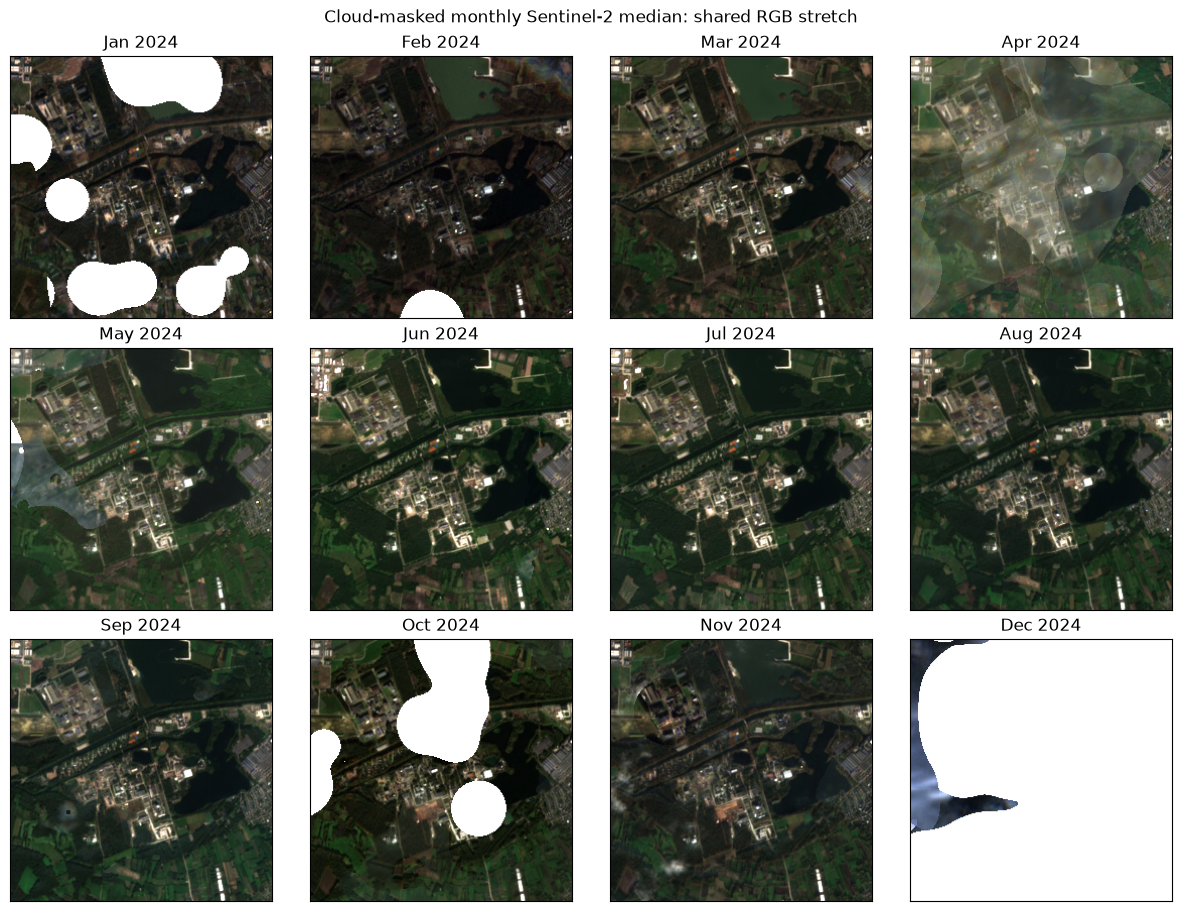

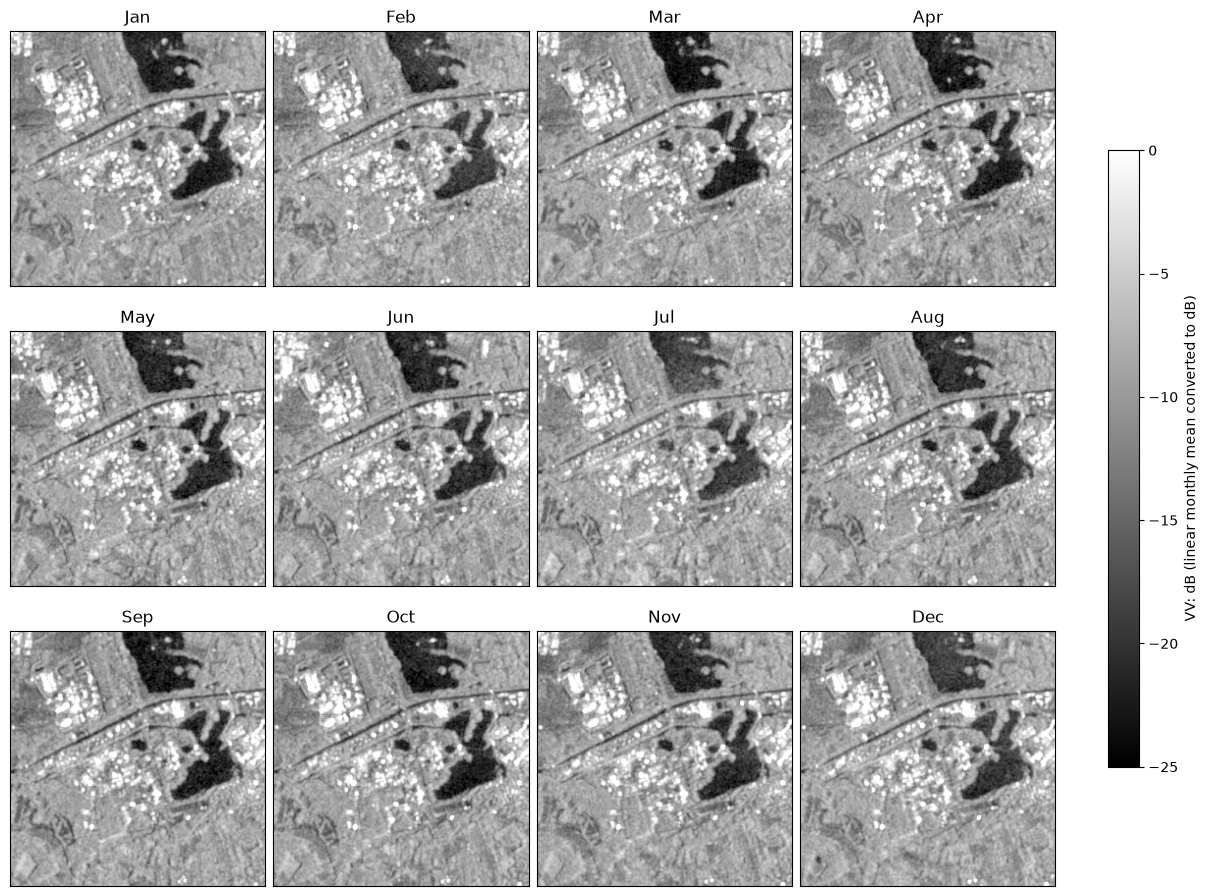

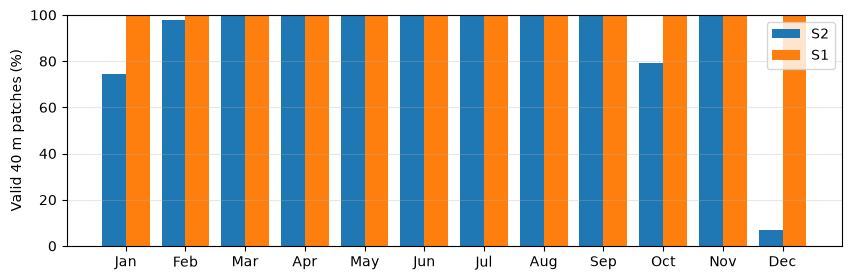

In [12]:
month_names = [date(YEAR, m, 1).strftime('%b') for m in range(1, 13)]
fig, axes = plt.subplots(3, 4, figsize=(12, 9), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    rgb = monthly[index, [2, 1, 0]].transpose(1, 2, 0) / 3000
    good = np.isfinite(rgb).all(axis=2)
    rgba = np.dstack([np.nan_to_num(np.clip(rgb, 0, 1)), good.astype(float)])
    ax.imshow(rgba, extent=[bounds[0], bounds[2], bounds[1], bounds[3]], origin='upper')
    ax.set_title(f'{month_names[index]} {YEAR}')
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Cloud-masked monthly Sentinel-2 median: shared RGB stretch')
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(12, 9), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    image = axes.flat[index].imshow(np.ma.masked_invalid(monthly[index, 12]), cmap='gray', vmin=-25, vmax=0)
    ax.set_title(month_names[index]); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(image, ax=axes.ravel().tolist(), label='VV: dB (linear monthly mean converted to dB)', shrink=0.7)
plt.show()

coverage = validity.sum(axis=(2, 3)) / validity.shape[-1] / validity.shape[-2] * 100
x = np.arange(12)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(x - 0.2, coverage[:, 0], width=0.4, label='S2')
ax.bar(x + 0.2, coverage[:, 1], width=0.4, label='S1')
ax.set_xticks(x, month_names); ax.set_ylim(0, 100)
ax.set_ylabel('Valid 40 m patches (%)'); ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.show()


### One annual PCA map and a georeferenced overlay

Fit PCA only to valid annual vectors; show its first three components with 2–98% channel stretches. These colors describe **relative variation within this AOI/year**, not classes. Independently fitted PCA maps have different axes/scales and are not directly comparable.

June RGB provides the background, retaining transparent clouded pixels. Repeating 40 m cells for the overlay does **not** add detail. Coordinate labels and the native raster bounds keep the RGB and embedding aligned.


Variance explained: [0.20661971 0.13136663 0.08245242]


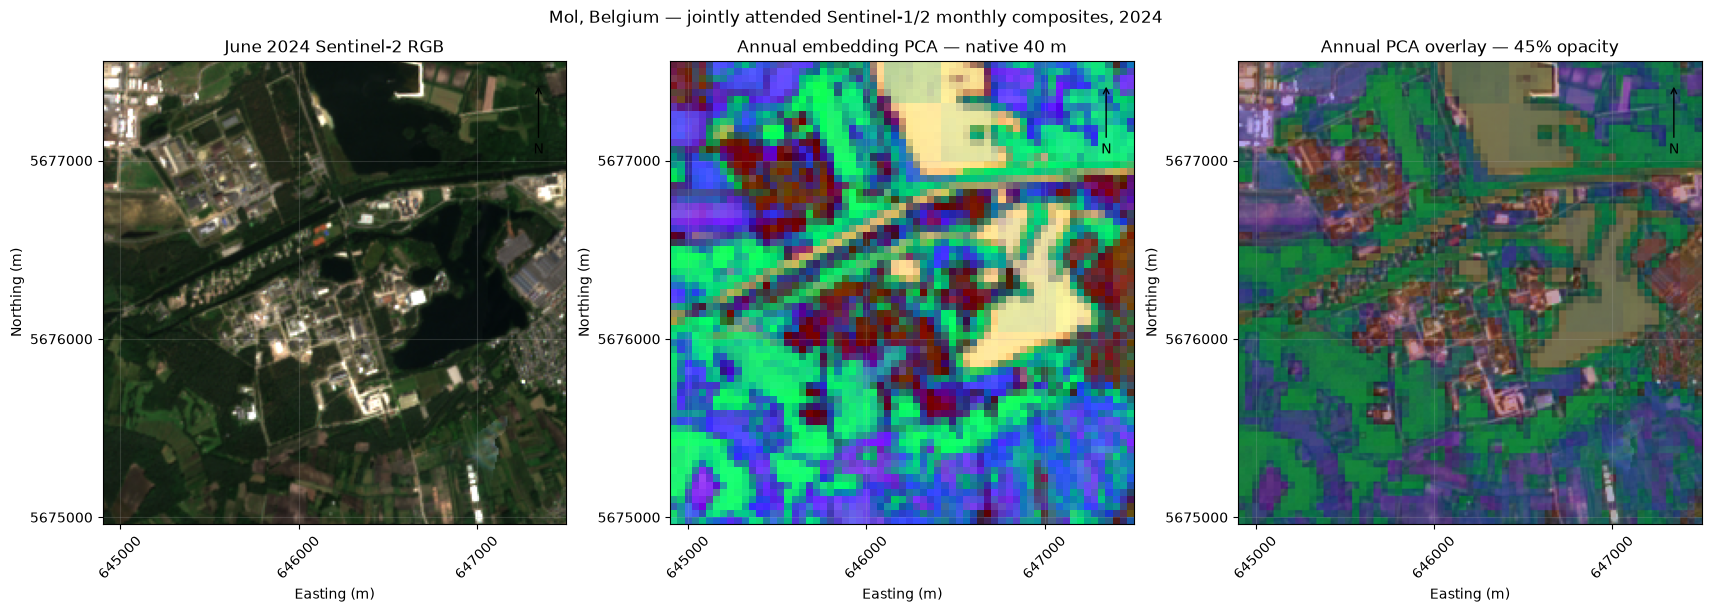

In [13]:
vectors = embeddings[:, annual_valid].T.astype(np.float64)
assert len(vectors) >= 4, 'Need at least four valid vectors for PCA'
center = vectors.mean(axis=0)
centered = vectors - center
eigenvalues, eigenvectors = np.linalg.eigh(centered.T @ centered / (len(vectors) - 1))
components = eigenvectors[:, -3:][:, ::-1]
scores = centered @ components
lo, hi = np.percentile(scores, [2, 98], axis=0)
colors = np.clip((scores - lo) / np.maximum(hi - lo, 1e-12), 0, 1)
pca = np.zeros((*annual_valid.shape, 4), dtype=np.float32)
pca[annual_valid, :3] = colors
pca[annual_valid, 3] = 1
print('Variance explained:', eigenvalues[-3:][::-1] / eigenvalues.sum())

background = monthly[5, [2, 1, 0]].transpose(1, 2, 0) / 3000
background_valid = np.isfinite(background).all(axis=2)
background = np.dstack([np.nan_to_num(np.clip(background, 0, 1)), background_valid.astype(float)])
overlay = np.repeat(np.repeat(pca, 4, axis=0), 4, axis=1)
overlay[..., 3] *= 0.45
extent = [bounds[0], bounds[2], bounds[1], bounds[3]]
fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
axes[0].imshow(background, extent=extent, origin='upper'); axes[0].set_title(f'June {YEAR} Sentinel-2 RGB')
axes[1].imshow(pca, extent=extent, origin='upper'); axes[1].set_title('Annual embedding PCA — native 40 m')
axes[2].imshow(background, extent=extent, origin='upper')
axes[2].imshow(overlay, extent=extent, origin='upper'); axes[2].set_title('Annual PCA overlay — 45% opacity')
for ax in axes:
    ax.xaxis.set_major_locator(MultipleLocator(1000)); ax.yaxis.set_major_locator(MultipleLocator(1000))
    ax.ticklabel_format(style='plain', useOffset=False); ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)'); ax.grid(alpha=0.2)
    ax.annotate('N', xy=(0.94, 0.95), xytext=(0.94, 0.80), xycoords='axes fraction',
                ha='center', arrowprops={'arrowstyle': '->', 'color': 'black'})
fig.suptitle(f'Mol, Belgium — jointly attended Sentinel-1/2 monthly composites, {YEAR}')
fig.savefig(folder / 'annual_embedding_pca.png', dpi=160, bbox_inches='tight')
plt.show()


## What this demonstrates—and what it does not

- A reusable **annual** feature cube built from twelve monthly Sentinel-1/2 composites using native `predict_onnx`, without retraining or a UDF.
- **Verified scope:** Nano on the full Mol 2024 default, and all four variants on a 320 m subset, with pretrained stock-PyTorch/ONNX checks and fresh CDSE batch runs. Every saved patch matched local ONNX Runtime. The saved figures remain Nano results; see the README for validated scope. Check numerical output and the grid rather than relying only on a colorful PCA image.
- **Not causal:** future months influence earlier tokens before annual pooling. This is unsuitable for an as-of-date task without a separately designed input strategy.
- **No spatial overlap:** 32×32 input tiles keep memory manageable, but attention stops at 320 m boundaries and seams may appear. The native patch spacing is 40 m, not the context size or an accuracy claim.
- **Missing data:** an invalid pixel/band discards its whole modality/month patch. Clouded/partial and single-modality cases are tested; entirely absent acquisition months and arbitrary regions/years are not backend-validated.
- **Preprocessing is backend-specific:** other backends may expose different collections, harmonization, SAR behavior or model processes. Do not normalize twice or copy WorldCereal's uint16 encoding.
- **Scaling:** full input stitching, local parity and plotting fit this small demonstration. Do not use those validation exports unchanged for very large AOIs.
- **No downstream assessment:** classification/clustering requires a separate task, labels where applicable, and independent evaluation. A possible next step is to train a classifier on the saved feature product; that is outside this notebook. Different variants require separately trained downstream models.
- **Licensing:** model artifacts and derivatives retain the restricted-use **[OlmoEarth Artifact License](https://huggingface.co/allenai/OlmoEarth-v1_2-Nano/blob/e1f693ae2a7d5b57871a978e9d09e22d05206747/LICENSE.txt)**. See [README](./README.md#licensing) and upstream terms before distributing weights or derived products.

Further reading: [Ai2 OlmoEarth](https://github.com/allenai/olmoearth_pretrain), [WorldCereal preprocessing reference](https://github.com/WorldCereal/worldcereal-classification/blob/temporary-global-udp-host/src/worldcereal/udp/global-production-udp-no-export-workspace-onnx.json), and the neighbouring [TerraMind example](../terramind/terramind-embedding.ipynb).
